In [62]:
import torch
from torch import nn

In [63]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [64]:
import requests
import zipfile
from pathlib import Path

data_path=Path("data/")
image_path=data_path/"pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} directory already exists... skipping download")
else:
    print(f"{image_path} does not exist,creating one...")
    image_path.mkdir(parents=True,exist_ok=True)

with open(data_path/"pizza_steak_sushi.zip","wb") as f:
    request=requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
    print("Downloading .....")
    f.write(request.content)

with zipfile.ZipFile(data_path/"pizza_steak_sushi.zip","r") as zip_ref:
    print("UNzipping .....")
    zip_ref.extractall(image_path)

data/pizza_steak_sushi directory already exists... skipping download
UNzipping .....


In [65]:
import os

def walk_through_dir(dir_path):
    """Walks through"""
    for dirpath,dirnames,filename in os.walk(dir_path):
        print(f"There are {len(dirnames)} directory and {len(filename)} images in '{dirpath}'.")

In [66]:
walk_through_dir(image_path)

There are 2 directory and 0 images in 'data/pizza_steak_sushi'.
There are 3 directory and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directory and 72 images in 'data/pizza_steak_sushi/train/sushi'.
There are 0 directory and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 0 directory and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 3 directory and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directory and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 0 directory and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 0 directory and 19 images in 'data/pizza_steak_sushi/test/steak'.


In [67]:
train_dir=image_path/"train"
test_dir=image_path/"test"

train_dir,test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [68]:
import random
from PIL import Image

# random.seed(42)


image_path_list=list(image_path.glob("*/*/*.jpg"))

image_path_list

[PosixPath('data/pizza_steak_sushi/train/sushi/1232045.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1214108.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/390178.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2019344.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/855721.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2813454.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2492146.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1280119.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1615453.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1551817.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/773725.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2641778.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/121940.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/3360232.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/3251688.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/1209865.jpg'),
 PosixPath('

In [69]:
len(image_path_list)

300

Random image path: data/pizza_steak_sushi/train/sushi/794647.jpg
Image class: sushi
Image height: 512
Image: 512


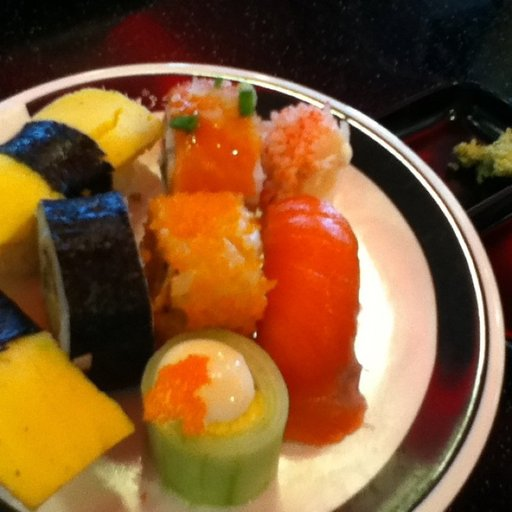

In [70]:
random_image_path=random.choice(image_path_list)

image_class=random_image_path.parent.stem

img=Image.open(random_image_path)

print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image: {img.width}")
img

In [71]:
import numpy as np
import matplotlib.pyplot as plt

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

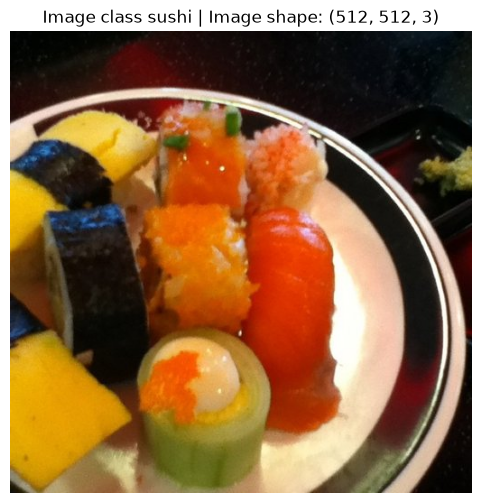

In [72]:
image_as_array=np.asarray(img)

plt.figure(figsize=(10,6))
plt.imshow(image_as_array)
plt.title(f"Image class {image_class} | Image shape: {image_as_array.shape}")
plt.axis(False)

In [73]:
image_as_array

array([[[ 1,  3,  2],
        [ 2,  4,  3],
        [ 2,  4,  3],
        ...,
        [17, 21, 22],
        [18, 22, 23],
        [19, 23, 24]],

       [[ 1,  3,  2],
        [ 2,  4,  3],
        [ 2,  4,  3],
        ...,
        [13, 17, 18],
        [14, 18, 19],
        [15, 19, 20]],

       [[ 1,  3,  2],
        [ 2,  4,  3],
        [ 2,  4,  3],
        ...,
        [12, 16, 17],
        [13, 17, 18],
        [14, 18, 19]],

       ...,

       [[18, 19, 11],
        [17, 18, 10],
        [18, 18, 10],
        ...,
        [ 4,  3,  1],
        [ 5,  4,  2],
        [ 5,  4,  2]],

       [[18, 20, 17],
        [18, 19, 14],
        [20, 19, 15],
        ...,
        [ 3,  2,  0],
        [ 4,  3,  1],
        [ 4,  3,  1]],

       [[15, 17, 16],
        [15, 17, 16],
        [18, 17, 15],
        ...,
        [ 3,  2,  0],
        [ 3,  2,  0],
        [ 4,  3,  1]]], shape=(512, 512, 3), dtype=uint8)

In [74]:
import torch 
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [75]:
data_trasnform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

In [76]:
data_trasnform(img).shape

torch.Size([3, 64, 64])

In [77]:
data_trasnform(img)

tensor([[[0.0471, 0.0157, 0.0196,  ..., 0.0078, 0.0078, 0.0078],
         [0.0471, 0.0314, 0.0196,  ..., 0.0118, 0.0118, 0.0078],
         [0.0588, 0.0431, 0.0275,  ..., 0.0157, 0.0157, 0.0078],
         ...,
         [0.0235, 0.0235, 0.0196,  ..., 0.7373, 0.6353, 0.5608],
         [0.0196, 0.0235, 0.0196,  ..., 0.6275, 0.5529, 0.3961],
         [0.0157, 0.0157, 0.0196,  ..., 0.5569, 0.3373, 0.1412]],

        [[0.0667, 0.0431, 0.0588,  ..., 0.0157, 0.0157, 0.0157],
         [0.0706, 0.0627, 0.0588,  ..., 0.0196, 0.0196, 0.0157],
         [0.0824, 0.0706, 0.0588,  ..., 0.0235, 0.0235, 0.0157],
         ...,
         [0.0196, 0.0196, 0.0157,  ..., 0.5451, 0.4980, 0.5020],
         [0.0157, 0.0196, 0.0157,  ..., 0.4980, 0.4941, 0.3686],
         [0.0118, 0.0118, 0.0157,  ..., 0.5020, 0.3098, 0.1216]],

        [[0.0667, 0.0510, 0.0745,  ..., 0.0118, 0.0118, 0.0118],
         [0.0588, 0.0588, 0.0667,  ..., 0.0157, 0.0157, 0.0118],
         [0.0667, 0.0667, 0.0667,  ..., 0.0118, 0.0118, 0.

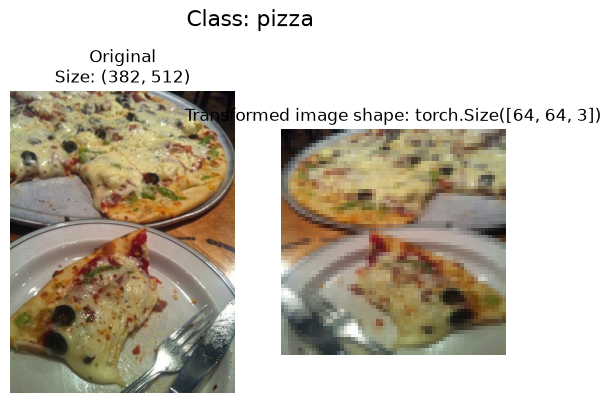

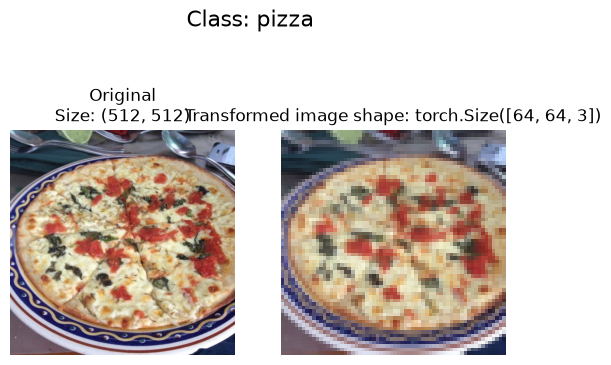

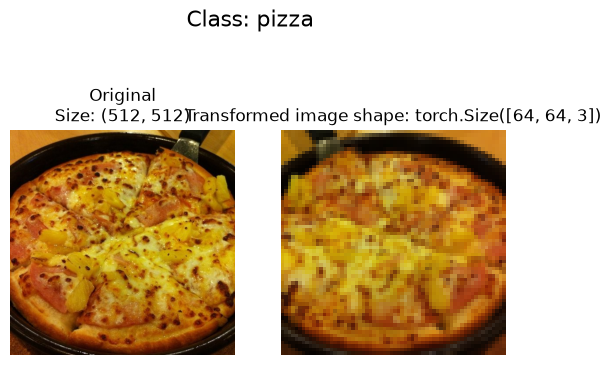

In [78]:
def plot_transformed_images(image_paths,transform,n=3,seed=42):
    if seed:
        random.seed(seed)

    random_image_paths=random.sample(image_paths,k=n)

    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig,ax=plt.subplots(nrows=1,ncols=2)

            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)

            transformed_image=transform(f).permute(1,2,0)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed image shape: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}",fontsize=16)
plot_transformed_images(image_paths=image_path_list,transform=data_trasnform,n=3,seed=None)

In [79]:
from torchvision import datasets

train_data=datasets.ImageFolder(root=train_dir,
                                transform=data_trasnform,
                                target_transform=None)

test_data=datasets.ImageFolder(root=test_dir,transform=data_trasnform)

train_data,test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [80]:
class_names=train_data.classes
class_names

['pizza', 'steak', 'sushi']

In [81]:
class_dict=train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [82]:
len(train_data),len(test_data)

(225, 75)

In [83]:
train_data.samples[0]

('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [84]:
img,label=train_data[0][0],train_data[0][1]
print(f"Image tensor:\n {img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image Label: {label}")
print(f"Label Datatype: {type(label)}")

Image tensor:
 tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.0

In [85]:
img_premute=img.permute(1,2,0)

print(img_premute.shape)

torch.Size([64, 64, 3])


In [86]:
import os
os.cpu_count()

12

In [87]:
from torch.utils.data import DataLoader

BATCH_SIZE=1

train_dataloader=DataLoader(dataset=train_data,batch_size=BATCH_SIZE,num_workers=1,shuffle=True)
test_dataloader=DataLoader(dataset=test_data,batch_size=BATCH_SIZE,num_workers=1,shuffle=False)

train_dataloader,test_dataloader


(<torch.utils.data.dataloader.DataLoader at 0x7ad4778cf0b0>,
 <torch.utils.data.dataloader.DataLoader at 0x7ad4768e7320>)

In [88]:
len(train_dataloader),len(test_dataloader)

(225, 75)

In [89]:
img,label=next(iter(train_dataloader))
print(f"Image: {img.shape} -> [batch_size,color_channels,height,weidth]")
print(f"Label shape: {label.shape}")

Image: torch.Size([1, 3, 64, 64]) -> [batch_size,color_channels,height,weidth]
Label shape: torch.Size([1])


In [90]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset

from torchvision import transforms
from typing import Tuple,Dict,List

In [91]:
train_data.classes,train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [92]:
target_directory=train_dir

print(f"Target dir: {target_directory}")

class_names_found=sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [93]:
list(os.scandir(target_directory))

[<DirEntry 'sushi'>, <DirEntry 'pizza'>, <DirEntry 'steak'>]

In [94]:
def find_classes(directory: str) -> Tuple[List[str],Dict[str,int]]:
    classes=sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}... please check file structurre=e")

    class_to_idx={class_name: i for i,class_name in enumerate(classes)}
    return classes,class_to_idx

In [95]:
find_classes(target_directory)

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [96]:
from torch.utils.data import Dataset

class ImageFolderCustom(Dataset):
    def __init__(self,targ_dir:str,transform=None):
        self.path=list(pathlib.Path(targ_dir).glob("*/*.jpg"))


        self.transform=transform

        self.classes,self.class_to_idx=find_classes(targ_dir)

    def load_image(self,index: int)->Image.Image:
        image_path=self.paths[index]
        return Image.open(image_path)

    def __len__(self)->int:
        return len(self.path)

    def __getitem__(self,index:int)->Tuple[torch.Tensor,int]:
        img=self.load_image(index)
        class_name=self.paths[index].parent.name
        class_idx=self.class_to_idx[class_name]

        if self.transform:
            return self.transform(img),class_idx
        else:
            return img,class_idx

    

In [97]:
from torchvision import transforms

train_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

test_transforms=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor()
])

In [98]:
train_data_custom=ImageFolderCustom(train_dir,train_transforms)
test_data_custom=ImageFolderCustom(test_dir,test_transforms)

In [99]:
train_data_custom,test_data_custom

(<__main__.ImageFolderCustom at 0x7ad4778ced50>,
 <__main__.ImageFolderCustom at 0x7ad4778dc0e0>)

In [100]:
len(test_data),len(test_data_custom)

(75, 75)

In [101]:
len(train_data),len(train_data_custom)

(225, 225)

In [102]:
train_data_custom.classes

['pizza', 'steak', 'sushi']

In [103]:
train_data_custom.class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [104]:
print(train_data_custom.classes==train_data.classes)
print(test_data_custom.classes==test_data.classes)

True
True


In [111]:
import torch
import random
import matplotlib.pyplot as plt
from typing import List, Optional


def display_random_images(
    dataset: torch.utils.data.Dataset,
    classes: Optional[List[str]] = None,
    n: int = 10,
    display_shape: bool = True,
    seed: int = None
):

    if n > 10:
        n = 10
        print("For display purposes, n shouldn't be larger than 10. Setting to 10.")

    if n < 1:
        raise ValueError("n must be at least 1")

    n = min(n, len(dataset))

    if n == 0:
        raise ValueError("Dataset is empty")

    if seed is not None:
        random.seed(seed)

    random_samples_idx = random.sample(
        range(len(dataset)),
        k=n
    )

    plt.figure(figsize=(18,8))

    for i, targ_sample in enumerate(random_samples_idx):

        targ_image, targ_label = dataset[targ_sample]

        targ_image_adjust = targ_image.permute(1, 2, 0)

        plt.subplot(1, n, i + 1)

        plt.imshow(targ_image_adjust)
        plt.axis("off")

        if classes is not None:
            title = f"Class: {classes[int(targ_label)]}"
        else:
            title = f"Label: {int(targ_label)}"

        if display_shape:
            title += f"\nShape: {targ_image_adjust.shape}"

        plt.title(title)

    plt.tight_layout()
    plt.show()

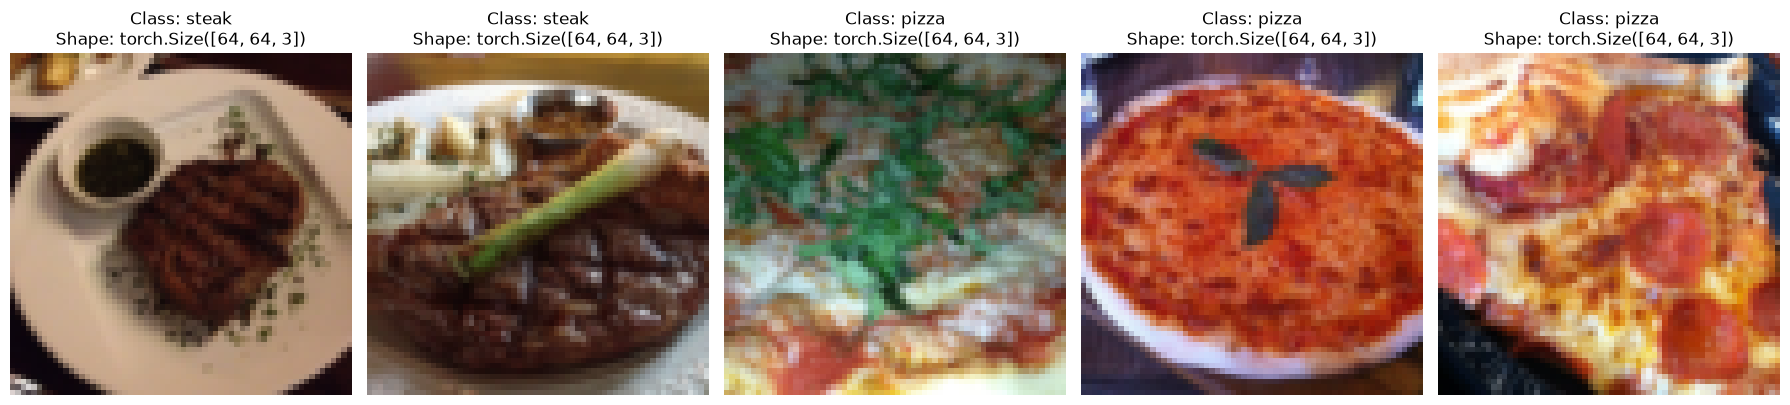

In [112]:
display_random_images(train_data,n=5,classes=class_names,seed=None)

For display purposes, n shouldn't be larger than 10. Setting to 10.


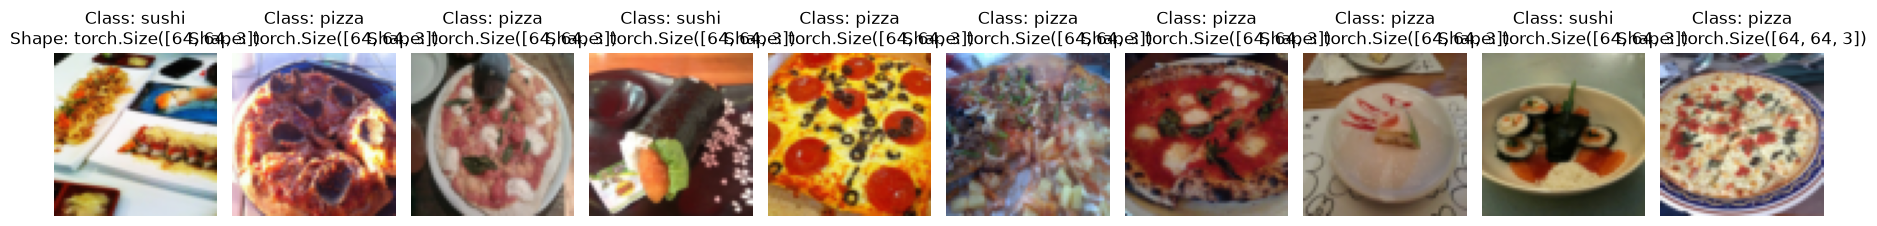

In [113]:
display_random_images(train_data,n=510,classes=class_names,seed=42)

In [ ]:
from torch.utils.data import Dataloader

BATCH_SIZE=32